# Chapter 5 — Linear Models and Regularization

> Reproduction notebook for **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025).

## Chapter Summary

Linear regression finds a mathematical relationship between features and a target that can be written as a line (OLS = Ordinary Least Squares). The chapter then shows how to **control model complexity** and how to model **non-linear** data.

| Recipe | Idea |
|---|---|
| Linear models | Fit $y=\beta_0+\beta_1x_1+\dots+\beta_nx_n+\epsilon$; evaluate with MSE and R² |
| Ridge & Lasso | Add an **L2** / **L1** penalty to the loss to shrink coefficients and fight overfitting |
| ElasticNet | Mix of L1 and L2 controlled by `alpha` and `l1_ratio` |
| Regularization theory | Penalties trade a little bias for a big drop in variance |
| Polynomial & spline regression | Extend linear models to curved relationships |

## 1. Introduction to linear models

**Theory.** Linear regression assumes a linear relationship:

$$y=\beta_0+\beta_1x_1+\beta_2x_2+\dots+\beta_nx_n+\epsilon$$

* $\beta_0$ intercept, $\beta_i$ coefficient of feature $i$, $\epsilon$ error term.
* OLS chooses the coefficients that minimise the **sum of squared errors** $\sum_i (y_i-\hat y_i)^2$.
* Metrics: **MSE** (mean squared error, lower is better) and **R²** (fraction of variance explained, higher is better).

The synthetic dataset (from `make_regression`) has **100 features, only 10 informative**, noise, and **multicollinearity** (features 50–99 are noisy copies of features 0–49) – a typical situation where plain OLS struggles and regularisation helps.

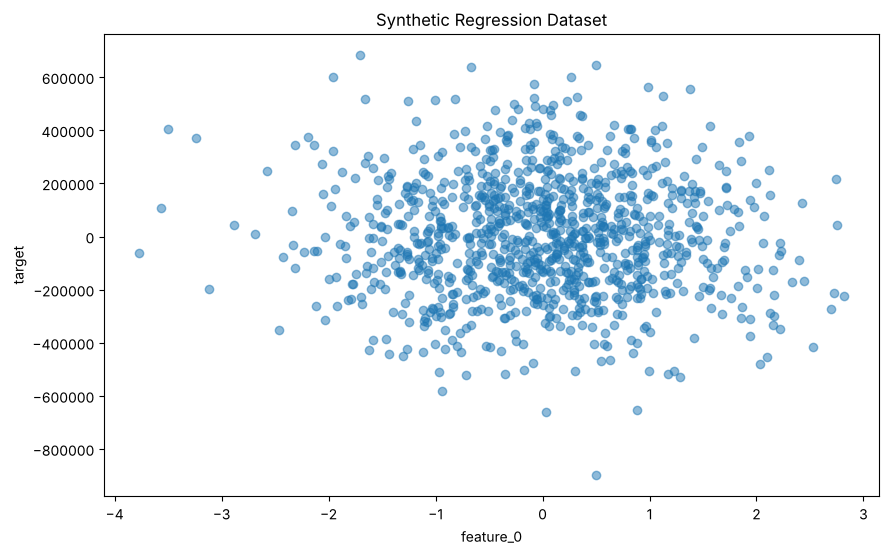

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

# Synthetic regression dataset with many features
X, y = make_regression(n_samples=1000,
                       n_features=100,
                       n_informative=10,
                       noise=20,
                       random_state=123)

# Add multicollinearity by creating correlated features
for i in range(50, 100):  # Make half the features correlated
    X[:, i] = X[:, i-50] + np.random.normal(0, 0.1, size=1000)

# Create feature names
feature_names = [f'feature_{i}' for i in range(100)]

# Take just the first feature for visualization
X_plot = X[:, 0].reshape(-1, 1)

# Add some non-linearity and make coefficients vary widely in magnitude
y = y * 1000  # Scale up the target
y = (y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10))

# Convert data arrays to a pandas DataFrame with feature names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df_plot = pd.DataFrame({'feature_0': X_plot.ravel(), 'target': y})

plt.figure(figsize=(10, 6))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Synthetic Regression Dataset')
plt.show()

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared: {r2:.2f}')

Mean Squared Error: 45930277801.43
R-squared: 0.08


/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


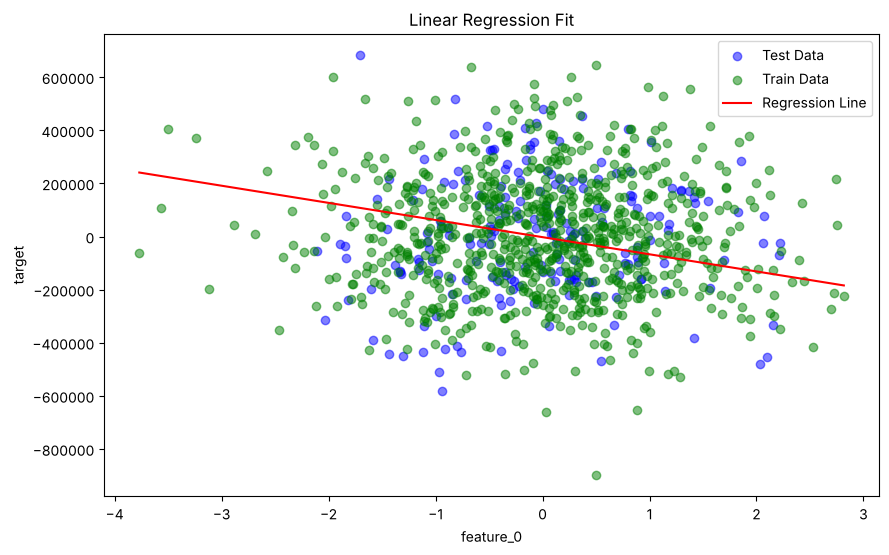

In [3]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')
plt.scatter(X_train[:, 0], y_train, color='green', alpha=0.5, label='Train Data')

# Regression line along feature_0 (other features held at 0)
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
y_line = linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names))

plt.plot(X_line, y_line, color='red', label='Regression Line')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Linear Regression Fit')
plt.legend()
plt.show()

**Next steps (book):** regularised regression (Ridge/Lasso penalties) and logistic regression (linear model for classification probabilities).

## 2. Ridge and Lasso regression

**Theory.** *Regularisation* adds a penalty term to the loss so the model prefers smaller coefficients, discouraging overly complex models.

* **Ridge (L2):** $\text{Loss}=\sum_i(y_i-\hat y_i)^2+\alpha\sum_j\beta_j^2$ — shrinks coefficients towards 0 but rarely to exactly 0 → keeps all features.
* **Lasso (L1):** $\text{Loss}=\sum_i(y_i-\hat y_i)^2+\alpha\sum_j|\beta_j|$ — can set coefficients to exactly 0 → built-in **feature selection**.
* `alpha` controls the strength of the penalty (larger = more shrinkage).

When to use which: Ridge when you want to keep all features but reduce their impact; Lasso when you suspect many features are irrelevant or redundant.

In [4]:
from sklearn.linear_model import Ridge, Lasso

ridge_model = Ridge(alpha=1.0)  # alpha controls regularization strength
ridge_model.fit(X_train, y_train)

lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)
y_pred_linear = linear_model.predict(X_test)

metrics = {
    'Model': ['Ridge Regression', 'Lasso Regression', 'Linear Regression'],
    'Mean Squared Error': [mean_squared_error(y_test, y_pred_ridge),
                           mean_squared_error(y_test, y_pred_lasso),
                           mean_squared_error(y_test, y_pred_linear)],
    'R-squared': [r2_score(y_test, y_pred_ridge),
                  r2_score(y_test, y_pred_lasso),
                  r2_score(y_test, y_pred_linear)],
}
metrics_df = pd.DataFrame(metrics).sort_values('Mean Squared Error', ascending=True)
metrics_df['Mean Squared Error'] = metrics_df['Mean Squared Error'].map('{:.2f}'.format)
metrics_df['R-squared'] = metrics_df['R-squared'].map('{:.2f}'.format)
display(metrics_df)

,Model,Mean Squared Error,R-squared
0,Ridge Regression,44446446951.93,0.11
1,Lasso Regression,45707221681.77,0.08
2,Linear Regression,45930277801.43,0.08


/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but Lasso was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


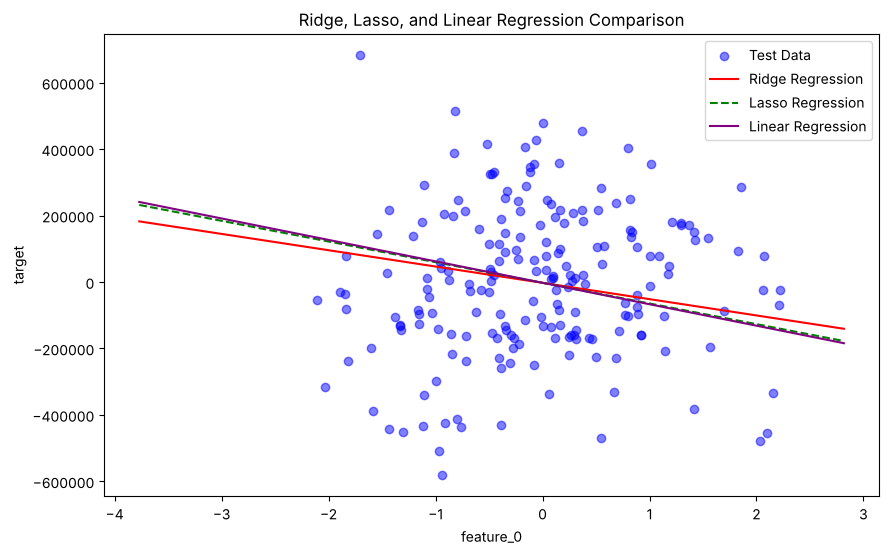

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=0.5, label='Test Data')

X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
X_line_df = pd.DataFrame(X_line_full, columns=feature_names)

plt.plot(X_line, ridge_model.predict(X_line_df), color='red', label='Ridge Regression')
plt.plot(X_line, lasso_model.predict(X_line_df), color='green', linestyle='--', label='Lasso Regression')
plt.plot(X_line, linear_model.predict(X_line_df), color='purple', label='Linear Regression')
plt.xlabel('feature_0')
plt.ylabel('target')
plt.title('Ridge, Lasso, and Linear Regression Comparison')
plt.legend()
plt.show()

In [6]:
# Extra illustration: how many coefficients did each model set to exactly 0?
print("Linear : non-zero coefs =", np.sum(linear_model.coef_ != 0))
print("Ridge  : non-zero coefs =", np.sum(ridge_model.coef_ != 0))
print("Lasso  : non-zero coefs =", np.sum(lasso_model.coef_ != 0))

Linear : non-zero coefs = 100
Ridge  : non-zero coefs = 100
Lasso  : non-zero coefs = 99


**Takeaway.** The differences in fit are small here because the data is highly multicollinear, but Lasso clearly performs feature selection. The book reminds us that even small improvements can matter in real applications.

## 3. ElasticNet and regularisation

**Theory.** ElasticNet combines both penalties:

$$\text{Loss}=\sum_i(y_i-\hat y_i)^2+\alpha\Big(\lambda_1\sum_j|\beta_j|+\lambda_2\sum_j\beta_j^2\Big)$$

* `alpha` — overall strength.
* `l1_ratio` — mix between the penalties: `1` = pure Lasso, `0` = pure Ridge, between = a blend.
* Useful when features are **correlated** (Lasso alone tends to pick one arbitrarily) and when there are more predictors than observations.

A **coefficient path plot** shows how each coefficient shrinks as `alpha` grows (x-axis in log scale). Coefficients that reach 0 have been dropped; those that resist shrinkage are the most important. With 100 features the plot is busy, but it shows the concept.

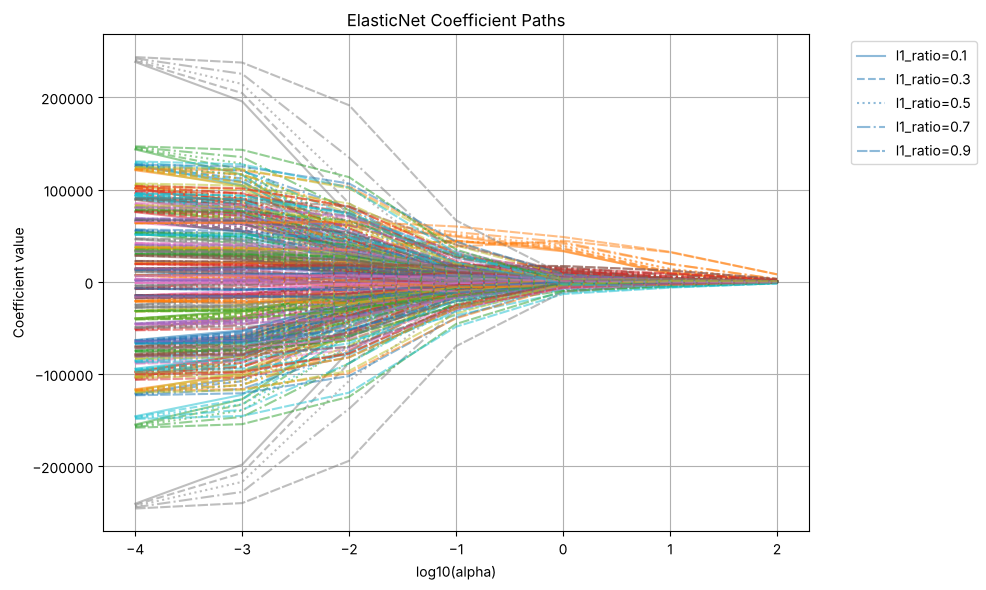

In [7]:
from sklearn.linear_model import ElasticNet

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
linestyles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 1))]

plt.figure(figsize=(10, 6))
for l1_ratio, ls in zip(l1_ratios, linestyles):
    coefs = []
    for alpha in alphas:
        elastic_model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio,
                                   random_state=123, max_iter=10000, tol=1e-4)
        elastic_model.fit(X_train, y_train)
        coefs.append(elastic_model.coef_)
    coefs = np.array(coefs)
    for feature_idx in range(X_train.shape[1]):
        plt.plot(np.log10(alphas), coefs[:, feature_idx], alpha=0.5, linestyle=ls,
                 label=f'l1_ratio={l1_ratio}' if feature_idx == 0 else "")

plt.xlabel('log10(alpha)')
plt.ylabel('Coefficient value')
plt.title('ElasticNet Coefficient Paths')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# ElasticNet with a balanced l1_ratio and moderate alpha
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4)
elastic_model.fit(X_train, y_train)

elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

# Rebuild a numeric comparison table including ElasticNet
all_metrics = pd.DataFrame({
    'Model': ['Ridge Regression', 'Lasso Regression', 'Linear Regression', 'ElasticNet Regression'],
    'Mean Squared Error': [mean_squared_error(y_test, y_pred_ridge), mean_squared_error(y_test, y_pred_lasso),
                           mean_squared_error(y_test, y_pred_linear), elastic_mse],
    'R-squared': [r2_score(y_test, y_pred_ridge), r2_score(y_test, y_pred_lasso),
                  r2_score(y_test, y_pred_linear), elastic_r2],
}).sort_values('Mean Squared Error', ascending=True)
display(all_metrics.round(4))

,Model,Mean Squared Error,R-squared
3,ElasticNet Regression,4.240935e+10,0.1480
0,Ridge Regression,4.444645e+10,0.1070
1,Lasso Regression,4.570722e+10,0.0817
2,Linear Regression,4.593028e+10,0.0772


## 4. Regularisation theory and practice

**Theory.**

* **Model complexity** = capacity to fit many functions. Complex models fit training data (even its noise) very well but generalise poorly → **overfitting**.
* Regularisation adds a penalty to the **loss function** so the model balances *goodness of fit* and *simplicity*, shrinking coefficients toward 0 (sparsity).
* **L1 (Lasso)** → sparse models, feature selection. **L2 (Ridge)** → small but non-zero coefficients. **ElasticNet** → both.
* **Bias–variance trade-off:** regularisation adds a little *bias* (the model is constrained) but strongly reduces *variance* (sensitivity to fluctuations in the training data). The goal is the level of regularisation that minimises error on **unseen** data.
* Going further: group Lasso (grouped features), Bayesian regression (priors on coefficients).

The cell below is a small extra demonstration (not in the book) of the bias–variance idea: training error rises and test error first falls, then rises as `alpha` grows.

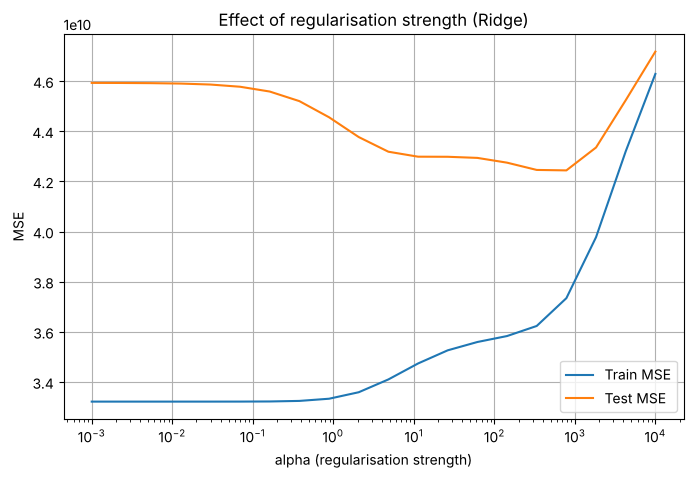

In [9]:
alpha_grid = np.logspace(-3, 4, 20)
train_err, test_err = [], []
for a in alpha_grid:
    m = Ridge(alpha=a).fit(X_train, y_train)
    train_err.append(mean_squared_error(y_train, m.predict(X_train)))
    test_err.append(mean_squared_error(y_test, m.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.semilogx(alpha_grid, train_err, label="Train MSE")
plt.semilogx(alpha_grid, test_err, label="Test MSE")
plt.xlabel("alpha (regularisation strength)"); plt.ylabel("MSE")
plt.title("Effect of regularisation strength (Ridge)")
plt.legend(); plt.grid(True)
plt.show()

## 5. Regression and regularisation: polynomial regression and splines

**Theory.** When the relationship is curved, plain linear regression underfits. Two ways to extend it:

* **Polynomial regression** – create powers of the feature ($x, x^2, x^3,\dots$) with `PolynomialFeatures`, then fit an ordinary linear regression on them:
  $y=\beta_0+\beta_1x+\beta_2x^2+\dots+\beta_nx^n+\epsilon$. Higher degree = more flexible but more prone to **overfitting**.
* **Spline interpolation** – split the range into segments separated by **knots** and fit a low-degree polynomial in each; segments join smoothly. `SplineTransformer(n_knots, degree)` does this.

The new dataset is $y = 2x + 27\sin(x/8) + \text{noise}$ (a line plus a sine wave).

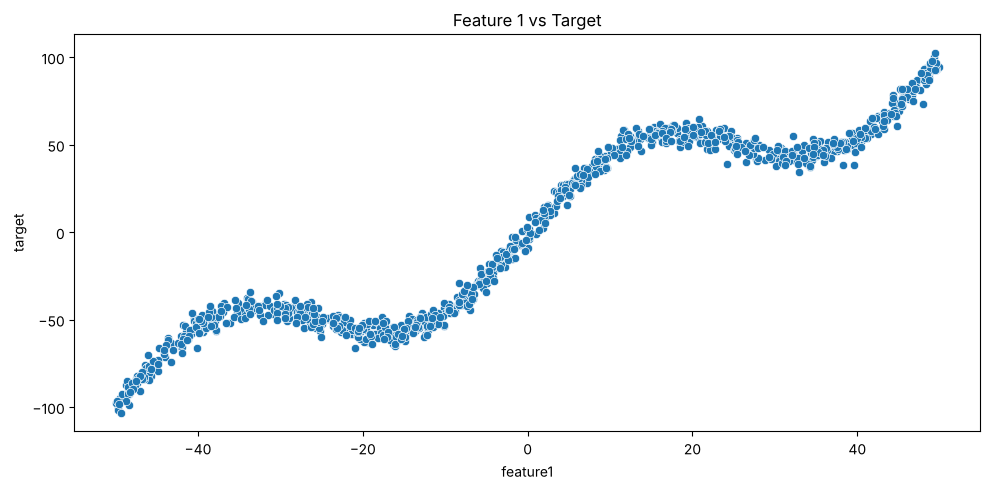

In [10]:
import seaborn as sns

np.random.seed(123)
n_samples = 1000
X = np.random.uniform(-50, 50, (n_samples, 1))

# Target with non-linear components
y = (2 * X[:, 0]                # linear component
     + 27 * np.sin(X[:, 0] / 8)  # non-linear component
     + np.random.normal(0, 4, n_samples))  # noise

data = pd.DataFrame(X, columns=['feature1'])
data['target'] = y

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='feature1', y='target')
plt.title('Feature 1 vs Target')
plt.tight_layout()
plt.show()

### 5.1 Polynomial regression with degrees 1–5

In [11]:
from sklearn.preprocessing import PolynomialFeatures

X = data[['feature1']]
y = data['target']

degrees = [1, 2, 3, 4, 5]
results = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)
    X_tr, X_te, y_tr, y_te = train_test_split(X_poly, y, test_size=0.2, random_state=123)

    poly_model = LinearRegression().fit(X_tr, y_tr)
    y_hat = poly_model.predict(X_te)
    results.append({'Degree': degree,
                    'MSE': mean_squared_error(y_te, y_hat),
                    'R2': r2_score(y_te, y_hat)})

results_df = pd.DataFrame(results)
print("Model Performance Metrics:")
print(results_df.to_string(index=False))

Model Performance Metrics:
 Degree        MSE       R2
      1 317.005037 0.891135
      2 316.818454 0.891199
      3 268.477397 0.907800
      4 268.230101 0.907885
      5 811.070884 0.721464


/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


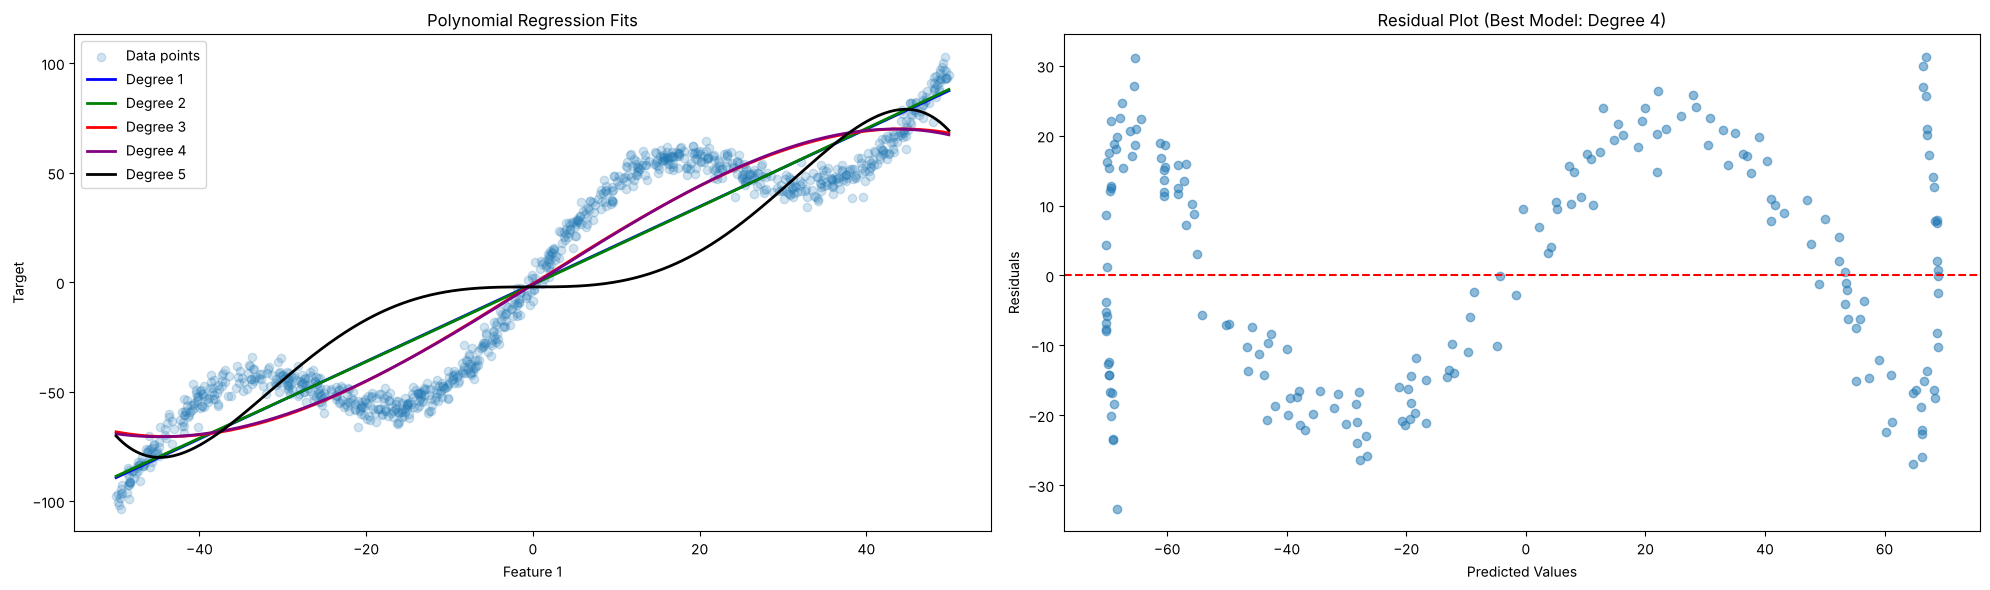

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

# Left: data and polynomial fits
ax1.scatter(X['feature1'], y, alpha=0.2, label='Data points')
X_plot = np.linspace(X['feature1'].min(), X['feature1'].max(), 1000).reshape(-1, 1)
colors = ['blue', 'green', 'red', 'purple', 'black']

for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree)
    model = LinearRegression().fit(poly.fit_transform(X), y)
    ax1.plot(X_plot, model.predict(poly.transform(X_plot)), label=f'Degree {degree}', color=color, linewidth=2)
ax1.set_xlabel('Feature 1'); ax1.set_ylabel('Target')
ax1.set_title('Polynomial Regression Fits'); ax1.legend(loc='upper left')

# Right: residuals for the best model (by R2)
best_degree = int(results_df.loc[results_df['R2'].idxmax(), 'Degree'])
best_poly = PolynomialFeatures(degree=best_degree)
X_poly_best = best_poly.fit_transform(X)
X_tr, X_te, y_tr, y_te = train_test_split(X_poly_best, y, test_size=0.2, random_state=123)
best_model = LinearRegression().fit(X_tr, y_tr)
y_hat = best_model.predict(X_te)
residuals = y_te - y_hat

ax2.scatter(y_hat, residuals, alpha=0.5)
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Values'); ax2.set_ylabel('Residuals')
ax2.set_title(f'Residual Plot (Best Model: Degree {best_degree})')
plt.tight_layout()
plt.show()

> Caution (from the book): the "best" degree by R² is not automatically the best model — a very flexible polynomial can capture noise that will not exist in real-world data. Use cross-validation to choose.

### 5.2 Spline interpolation

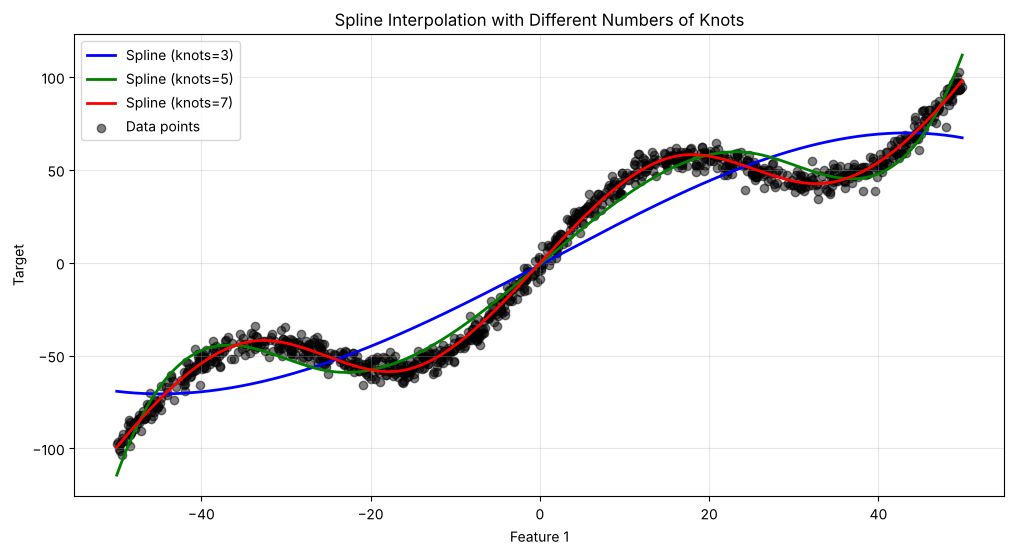

,Number of Knots,MSE,R-squared
0,3,274.267019,0.904652
1,5,55.347798,0.980759
2,7,15.502097,0.994611


In [13]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline

n_knots = [3, 5, 7]   # Different numbers of knots to try
plt.figure(figsize=(12, 6))
mse_scores, r2_scores = [], []

for n_knot, color in zip(n_knots, colors[:len(n_knots)]):
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X, y)

    y_pred_curve = model.predict(pd.DataFrame(X_plot, columns=['feature1']))
    y_pred_train = model.predict(X)

    mse_scores.append(mean_squared_error(y, y_pred_train))
    r2_scores.append(r2_score(y, y_pred_train))
    plt.plot(X_plot, y_pred_curve, label=f'Spline (knots={n_knot})', color=color, linewidth=2)

plt.scatter(X, y, color='black', alpha=0.5, label='Data points')
plt.xlabel('Feature 1'); plt.ylabel('Target')
plt.title('Spline Interpolation with Different Numbers of Knots')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

metrics_df = pd.DataFrame({'Number of Knots': n_knots, 'MSE': mse_scores, 'R-squared': r2_scores})
display(metrics_df)

More knots → lower MSE (better fit on the training data). Further reading from the book: B-splines and natural splines.

## 6. Practical exercises with regularisation techniques

The exercises ask the reader to build a new dataset and fit Ridge, Lasso and ElasticNet in turn, using `random_state=123` for reproducibility. The steps: load libraries → generate synthetic data with noise → split → fit → predict → compute metrics → print → visualise (sort X for a smooth line).
Below is one combined implementation of the three exercises on the same data so they can be compared directly.

Exercise 1: Ridge        MSE= 14.512  R2=0.955
Exercise 2: Lasso        MSE= 14.521  R2=0.955
Exercise 3: ElasticNet   MSE= 14.532  R2=0.954


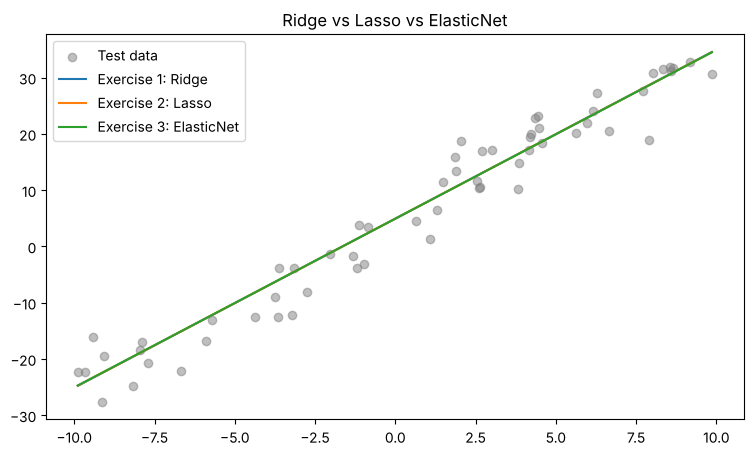

In [14]:
np.random.seed(123)
Xe = np.random.uniform(-10, 10, (300, 1))
ye = 3 * Xe[:, 0] + 5 + np.random.normal(0, 4, 300)       # noisy line
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(Xe, ye, test_size=0.2, random_state=123)

models = {
    "Exercise 1: Ridge": Ridge(alpha=1.0),
    "Exercise 2: Lasso": Lasso(alpha=0.1),
    "Exercise 3: ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=123),
}

order = np.argsort(Xe_te[:, 0])     # sort X for a smooth line plot
plt.figure(figsize=(9, 5))
plt.scatter(Xe_te, ye_te, alpha=0.5, color="gray", label="Test data")
for name, m in models.items():
    m.fit(Xe_tr, ye_tr)
    pred = m.predict(Xe_te)
    print(f"{name:24s} MSE={mean_squared_error(ye_te, pred):7.3f}  R2={r2_score(ye_te, pred):.3f}")
    plt.plot(Xe_te[order], pred[order], label=name)
plt.legend(); plt.title("Ridge vs Lasso vs ElasticNet"); plt.show()

---
### Chapter 5 key takeaways
1. Linear regression models a straight-line relationship; judge it with MSE and R².
2. **Ridge (L2)** shrinks coefficients, **Lasso (L1)** can zero them out (feature selection), **ElasticNet** blends both — ideal with correlated features.
3. Regularisation trades a bit of bias for a large reduction in variance, improving generalisation.
4. For curved relationships use **polynomial features** or **splines**, but guard against overfitting.